# 02 — Modelos de classificação com scikit-learn

Neste notebook treinamos, ajustamos e avaliamos os três algoritmos escolhidos na Fase 1:

| Algoritmo | Família | Ideia central |
|---|---|---|
| **Regressão Logística** | Linear, probabilística | Uma fronteira de decisão linear; a probabilidade vem da função sigmoide. |
| **K-Vizinhos Mais Próximos (KNN)** | Baseado em instâncias (distâncias) | Uma paciente é classificada pelo voto das *k* pacientes de treino mais parecidas. |
| **Random Forest** | Conjunto (*ensemble*) de árvores | Muitas árvores de decisão, cada uma treinada em uma amostra diferente, votam juntas. |

### Metodologia: treino, validação e teste

| Etapa | Dados usados | Para quê |
|---|---|---|
| **Treino** | 614 pacientes de `treino.csv` | Ajustar os parâmetros internos dos modelos (pesos, árvores...). |
| **Validação** (seleção de modelo) | Validação cruzada **dentro** do treino | Escolher hiperparâmetros e o limiar de decisão. |
| **Teste** | 154 pacientes de `teste.csv` | **Uma única** avaliação final de cada modelo já escolhido. Nenhuma decisão é tomada com base nele. |

Os arquivos `data/splits/treino.csv` e `teste.csv` são os mesmos que o Orange vai usar na Fase 4.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import RocCurveDisplay, make_scorer, precision_recall_curve, precision_score
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

from diabetes.config import FEATURES, RANDOM_SEED, TABLES_DIR
from diabetes.data import load_splits
from diabetes.evaluation import (METRIC_ORDER, best_threshold_fbeta, bootstrap_ci, compute_metrics,
                                 plot_confusion_matrix)
from diabetes.plotting import CLASS_COLORS, NEUTRAL, apply_style, save_fig
from diabetes.preprocessing import build_preprocessor

apply_style()
pd.set_option("display.precision", 3)
warnings.filterwarnings("ignore", category=FutureWarning)

X_train, y_train, X_test, y_test = load_splits()
print(f"Treino: {X_train.shape[0]} pacientes ({y_train.mean():.1%} com diabetes)")
print(f"Teste:  {X_test.shape[0]} pacientes ({y_test.mean():.1%} com diabetes, {y_test.sum()} diabéticas)")
print("Valores ausentes no treino:", X_train.isna().sum()[lambda s: s > 0].to_dict())

Treino: 614 pacientes (34.9% com diabetes)
Teste:  154 pacientes (35.1% com diabetes, 54 diabéticas)
Valores ausentes no treino: {'Glicose': 4, 'PressaoArterial': 23, 'Espesura_da_Pele': 175, 'Insulina': 290, 'IMC': 9}


## 1. O pipeline de pré-processamento

As decisões da EDA (notebook 01, §10) estão implementadas em `src/diabetes/preprocessing.py`:

1. **Zeros → NaN** nas cinco colunas em que zero é impossível (etapa sem estado).
2. **Imputação pela mediana** (`SimpleImputer`): aprende a mediana de cada coluna.
3. **Padronização** (`StandardScaler`): aprende a média μ e o desvio σ e transforma $x \mapsto (x-\mu)/\sigma$.

**Por que um `Pipeline`?** O modelo final é `Pipeline([pré-processamento, classificador])`. Quando a validação cruzada chama `fit` em 4 dos 5 folds, a mediana, μ e σ são calculados **apenas nesses 4 folds**, e o fold de validação é transformado com os valores aprendidos. Se padronizássemos o treino inteiro antes da validação cruzada, as estatísticas do fold de validação "vazariam" para o treino e a estimativa de desempenho ficaria otimista. O `Pipeline` garante isso automaticamente.

In [2]:
build_preprocessor()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('zeros_para_nan', ...), ('imputacao', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function _ze...0015F9342B4C0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword argumen

In [3]:
prep_demo = build_preprocessor().fit(X_train)
learned = pd.DataFrame({
    "mediana_imputada": prep_demo.named_steps["imputacao"].statistics_,
    "média_μ": prep_demo.named_steps["padronizacao"].mean_,
    "desvio_σ": prep_demo.named_steps["padronizacao"].scale_,
}, index=FEATURES)
learned.to_csv(TABLES_DIR / "parametros_preprocessamento_treino.csv")
learned

,mediana_imputada,média_μ,desvio_σ
Gavidez,3.000,3.819,3.311
Glicose,117.000,121.671,29.979
PressaoArterial,72.000,72.140,12.265
Espesura_da_Pele,29.000,29.042,8.885
Insulina,125.000,137.705,78.701
IMC,32.400,32.448,6.819
Diabetes_Hereditaria,0.383,0.477,0.330
Idade,29.000,33.366,11.824


Estes são os valores aprendidos **no conjunto de treino completo**, que o modelo final usa para transformar o teste. As **medianas** serão reutilizadas no Orange (Fase 4) caso ele não ofereça imputação pela mediana.

## 2. Os algoritmos

### 2.1 Regressão Logística

**Conceito.** Calcula um escore linear $z = \mathbf{x}\cdot\mathbf{w} + b$ e o converte em probabilidade com a sigmoide, $\hat p = 1/(1+e^{-z})$. A fronteira de decisão ($\hat p = 0{,}5$, ou seja, $z = 0$) é um **hiperplano**. O treino minimiza a entropia cruzada binária; o notebook 03 deriva e implementa tudo isso à mão.

**Regularização.** O scikit-learn minimiza $\; C\sum_i \text{BCE}_i + \tfrac{1}{2}\lVert\mathbf{w}\rVert^2$ (penalidade L2, ou *Ridge*). O termo $\lVert\mathbf{w}\rVert^2$ "puxa" os pesos para zero, o que reduz o *overfitting*. **C é o inverso da força da regularização**: C pequeno significa regularização forte (modelo mais simples) e C grande significa regularização fraca.

**Por que é adequada aqui:** é o modelo de referência para dados tabulares médicos pequenos. É estável, rápida e **interpretável**, pois cada coeficiente vira uma razão de chances. Sua limitação é supor que o log-odds varia **linearmente** com as variáveis.

**Pré-processamento:** imputação e **padronização** (a penalidade trata todos os coeficientes igualmente, então as variáveis precisam estar na mesma escala).

**Hiperparâmetro ajustado:** `C` ∈ {0,001; 0,01; 0,1; 1; 10; 100}. *No Orange:* widget *Logistic Regression*, regularização *Ridge (L2)*, parâmetro **C**.

### 2.2 K-Vizinhos Mais Próximos (KNN)

**Conceito.** Não existe uma fase de treino propriamente dita: o modelo **memoriza** as pacientes de treino (*lazy learning*). Para classificar uma nova paciente, encontra as *k* pacientes de treino mais próximas e usa a proporção de diabéticas entre elas como probabilidade.

- **k** controla o equilíbrio entre viés e variância. Com k = 1 o modelo segue cada ruído do treino (alta variância); com k grande ele suaviza demais (alto viés).
- **Distância:** euclidiana $\sqrt{\sum_j (x_j - x'_j)^2}$ ou Manhattan $\sum_j |x_j - x'_j|$.
- **Pesos:** *uniform* (cada vizinho vale 1 voto) ou *distance* (vizinhos mais próximos pesam mais, com peso 1/distância).

**Por que é adequado aqui:** representa uma abordagem completamente diferente (similaridade entre pacientes, sem nenhuma suposição sobre o formato da fronteira) e mostra claramente por que o pré-processamento importa.

**Pré-processamento:** imputação e **padronização obrigatória**. Sem ela, `Insulina` (escala de centenas) dominaria a distância e `Diabetes_Hereditaria` (escala < 2,5) seria praticamente ignorada.

**Hiperparâmetros ajustados:** `k` ∈ {1, 3, 5, …, 51}, distância ∈ {euclidiana, Manhattan}, pesos ∈ {uniform, distance}. *No Orange:* widget *kNN*: **Number of neighbors**, **Metric**, **Weight**.

### 2.3 Random Forest

**Conceito.** Uma **árvore de decisão** divide os dados com perguntas do tipo "Glicose ≤ 127,5?", escolhendo em cada nó a divisão que mais reduz a **impureza de Gini**, $G = 1 - \sum_c p_c^2$. Uma árvore sozinha é instável: pequenas mudanças nos dados mudam muito a árvore. O Random Forest combina centenas de árvores com duas fontes de aleatoriedade:

1. ***Bagging***: cada árvore é treinada em uma amostra *bootstrap* (sorteada com reposição) das pacientes.
2. **Subconjunto aleatório de variáveis**: em cada nó, só `max_features` variáveis sorteadas podem ser usadas.

Isso torna as árvores **pouco correlacionadas entre si**, e a média dos seus votos tem **variância muito menor** que uma árvore isolada.

**Por que é adequado aqui:** captura relações **não lineares** e **interações** (por exemplo, glicose alta *e* IMC alto) que a regressão logística não representa, é robusto a outliers e fornece importâncias das variáveis.

**Pré-processamento:** só imputação. A padronização não altera nada, pois as árvores dependem apenas da ordem dos valores. Ela é mantida para que o pipeline seja o mesmo para todos os modelos.

**Hiperparâmetros:**
- `n_estimators` = 300, **fixo**. Mais árvores nunca pioram o modelo, só custam tempo, então isso não é algo a ajustar.
- `max_depth` ∈ {sem limite, 4, 8}: profundidade máxima das árvores.
- `min_samples_split` ∈ {2, 10, 20}: nós com menos pacientes que isso não são divididos.
- `max_features` ∈ {2, 3, 4}: variáveis sorteadas por nó. O padrão do scikit-learn é $\lfloor\sqrt{8}\rfloor = 2$.

A grade usa **apenas parâmetros que o Orange também oferece**. *No Orange:* widget *Random Forest*: **Number of trees**, **Number of attributes considered at each split**, **Limit depth of individual trees**, **Do not split subsets smaller than**, e **Replicable training** marcado.

## 3. Ajuste de hiperparâmetros com validação cruzada

Para cada algoritmo, `GridSearchCV` testa **todas as combinações** da grade com **validação cruzada estratificada 5-fold repetida 2 vezes** (10 avaliações por combinação), sempre dentro do conjunto de treino.

**Critério de escolha: ROC-AUC.** A ROC-AUC mede a capacidade do modelo de **ordenar** as pacientes (diabéticas com probabilidade maior que não diabéticas), **independentemente do limiar** de decisão. Por que não escolher pelo recall, que é a métrica que mais nos importa? Porque o recall é trivial de maximizar: um modelo que diz "diabetes" para todas tem recall 1. A estratégia adotada separa as duas decisões:

1. Escolher os hiperparâmetros que produzem as **melhores probabilidades** (ROC-AUC) — aqui.
2. Escolher **onde cortar** essas probabilidades para priorizar o recall — na §6.

In [4]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_SEED)
scoring = {
    "roc_auc": "roc_auc",
    "acurácia": "accuracy",
    "precisão": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
    "f1": "f1",
}

MODEL_SPECS = {
    "Regressão Logística": (
        LogisticRegression(max_iter=5000),
        {"modelo__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    ),
    "KNN": (
        KNeighborsClassifier(),
        {"modelo__n_neighbors": list(range(1, 52, 2)),
         "modelo__metric": ["euclidean", "manhattan"],
         "modelo__weights": ["uniform", "distance"]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_SEED, n_jobs=-1),
        {"modelo__max_depth": [None, 4, 8],
         "modelo__min_samples_split": [2, 10, 20],
         "modelo__max_features": [2, 3, 4]},
    ),
}

searches = {}
for name, (estimator, grid) in MODEL_SPECS.items():
    pipe = Pipeline([("prep", build_preprocessor()), ("modelo", estimator)])
    search = GridSearchCV(pipe, grid, cv=cv, scoring=scoring, refit="roc_auc", n_jobs=1)
    search.fit(X_train, y_train)
    searches[name] = search
    print(f"{name:20s} {len(search.cv_results_['params']):3d} combinações | melhor: "
          f"{ {k.replace('modelo__', ''): v for k, v in search.best_params_.items()} }")

Regressão Logística    6 combinações | melhor: {'C': 0.1}


KNN                  104 combinações | melhor: {'metric': 'euclidean', 'n_neighbors': 43, 'weights': 'distance'}


Random Forest         27 combinações | melhor: {'max_depth': 4, 'max_features': 3, 'min_samples_split': 2}


In [5]:
rows = []
for name, search in searches.items():
    res, i = search.cv_results_, search.best_index_
    row = {"modelo": name}
    for m in scoring:
        row[m] = f"{res[f'mean_test_{m}'][i]:.3f} ± {res[f'std_test_{m}'][i]:.3f}"
    rows.append(row)
cv_summary = pd.DataFrame(rows).set_index("modelo")
cv_summary.to_csv(TABLES_DIR / "cv_melhores_modelos_python.csv")

best_params = pd.DataFrame(
    [(name, k.replace("modelo__", ""), v) for name, s in searches.items() for k, v in s.best_params_.items()],
    columns=["modelo", "hiperparâmetro", "valor"])
best_params.to_csv(TABLES_DIR / "hiperparametros_python.csv", index=False)

display(best_params)
print("Desempenho na validação cruzada (média ± desvio-padrão em 10 folds, limiar 0,5):")
cv_summary

,modelo,hiperparâmetro,valor
0,Regressão Logística,C,0.1
1,KNN,metric,euclidean
2,KNN,n_neighbors,43
3,KNN,weights,distance
4,Random Forest,max_depth,4
5,Random Forest,max_features,3
6,Random Forest,min_samples_split,2


Desempenho na validação cruzada (média ± desvio-padrão em 10 folds, limiar 0,5):


,roc_auc,acurácia,precisão,recall,f1
modelo,,,,,
Regressão Logística,0.845 ± 0.026,0.780 ± 0.036,0.748 ± 0.077,0.568 ± 0.085,0.640 ± 0.070
KNN,0.838 ± 0.037,0.763 ± 0.031,0.729 ± 0.087,0.531 ± 0.060,0.609 ± 0.045
Random Forest,0.841 ± 0.040,0.764 ± 0.041,0.726 ± 0.091,0.538 ± 0.083,0.612 ± 0.070


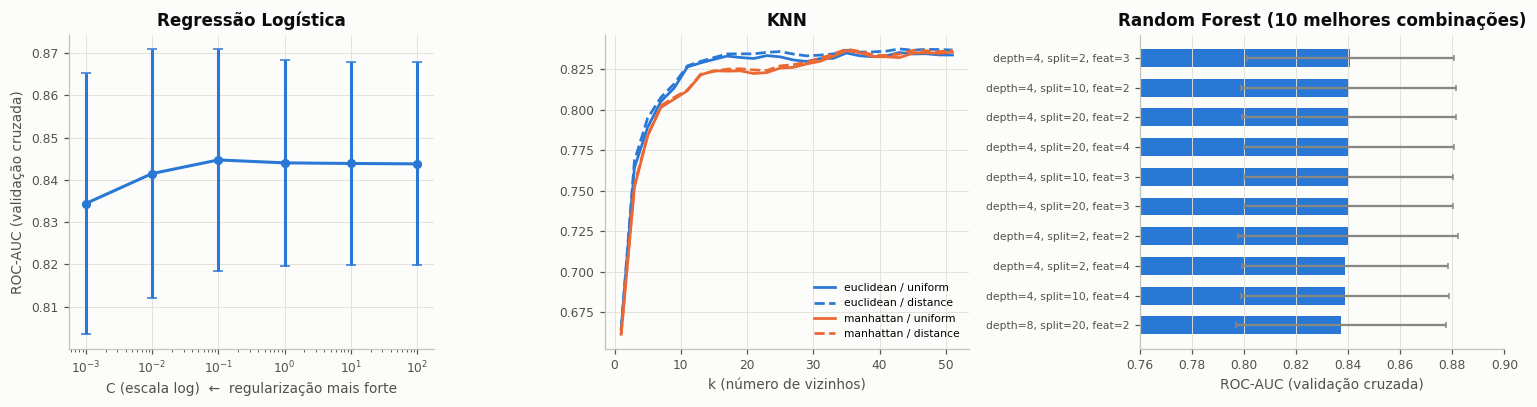

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

# Regressão Logística: AUC x C
res = pd.DataFrame(searches["Regressão Logística"].cv_results_)
ax = axes[0]
ax.errorbar(res["param_modelo__C"].astype(float), res["mean_test_roc_auc"], yerr=res["std_test_roc_auc"],
            color="#2a78d6", marker="o", markersize=5, linewidth=2, capsize=3)
ax.set_xscale("log")
ax.set_xlabel("C (escala log)  ←  regularização mais forte")
ax.set_ylabel("ROC-AUC (validação cruzada)")
ax.set_title("Regressão Logística")

# KNN: AUC x k, uma linha por combinação de distância e pesos
res = pd.DataFrame(searches["KNN"].cv_results_)
ax = axes[1]
styles = {("euclidean", "uniform"): ("#2a78d6", "-"), ("euclidean", "distance"): ("#2a78d6", "--"),
          ("manhattan", "uniform"): ("#eb6834", "-"), ("manhattan", "distance"): ("#eb6834", "--")}
for (metric, weights), (color, ls) in styles.items():
    sub = res[(res["param_modelo__metric"] == metric) & (res["param_modelo__weights"] == weights)]
    ax.plot(sub["param_modelo__n_neighbors"].astype(int), sub["mean_test_roc_auc"], color=color,
            linestyle=ls, linewidth=1.8, label=f"{metric} / {weights}")
ax.set_xlabel("k (número de vizinhos)")
ax.set_title("KNN")
ax.legend(fontsize=7)

# Random Forest: as 10 melhores combinações
res = pd.DataFrame(searches["Random Forest"].cv_results_).sort_values("mean_test_roc_auc", ascending=False)
ax = axes[2]
labels = [f"depth={p['modelo__max_depth']}, split={p['modelo__min_samples_split']}, feat={p['modelo__max_features']}"
          for p in res["params"]]
ax.barh(labels[:10][::-1], res["mean_test_roc_auc"][:10][::-1], color="#2a78d6", height=0.6,
        xerr=res["std_test_roc_auc"][:10][::-1], error_kw={"ecolor": NEUTRAL, "capsize": 2})
ax.set_xlim(0.76, 0.90)
ax.set_xlabel("ROC-AUC (validação cruzada)")
ax.set_title("Random Forest (10 melhores combinações)")
ax.tick_params(axis="y", labelsize=7)
ax.grid(axis="y", visible=False)

fig.tight_layout()
save_fig(fig, "10_ajuste_hiperparametros")
plt.show()

**Observações**

- **Hiperparâmetros escolhidos:**
  - Regressão Logística: **C = 0,1**, uma regularização moderada.
  - KNN: **k = 43**, distância **euclidiana**, pesos por **distância**.
  - Random Forest: **profundidade máxima 4**, **3 variáveis por nó**, `min_samples_split` = 2.
- **Regressão Logística.** A ROC-AUC quase não muda para C ≥ 0,01. Só a regularização mais forte (C = 0,001) piora um pouco. Com 8 variáveis e 614 pacientes, o modelo linear tem pouco espaço para *overfitting*, então a regularização importa pouco.
- **KNN.** Com k pequeno a ROC-AUC é baixa: k = 1 dá ≈ 0,66, porque o modelo segue o ruído de cada paciente (alta variância). Ela sobe rapidamente até k ≈ 15 e depois se estabiliza por volta de 0,83–0,84. O k = 43 escolhido fica nesse platô: valores entre ≈ 30 e 51 são praticamente equivalentes. A distância euclidiana fica ligeiramente acima da Manhattan; a diferença entre pesos *uniform* e *distance* é mínima.
- **Random Forest.** As melhores combinações limitam a **profundidade a 4**. Árvores rasas generalizam melhor neste dataset pequeno e ruidoso que árvores sem limite, que tendem a memorizar o treino. As 10 melhores combinações ficam todas dentro de ≈ 0,005 de AUC, muito menos que o desvio-padrão (≈ 0,04).
- **Comparação na validação cruzada:** ROC-AUC de **0,845** (RL), **0,841** (RF) e **0,838** (KNN). As diferenças (< 0,01) são bem menores que os desvios-padrão (0,026–0,040): **os três modelos estão empatados** em capacidade de ordenar as pacientes. Com o limiar 0,5, o recall na validação cruzada fica entre **0,53 e 0,57**: cerca de metade das diabéticas não é detectada.

## 4. Avaliação final no conjunto de teste (limiar 0,5)

Os modelos escolhidos foram **retreinados no treino completo** (o `GridSearchCV` faz isso com `refit`) e agora fazem previsões, **uma única vez**, para as 154 pacientes de teste.

### As métricas e o que significam neste problema

Na matriz de confusão, **positivo = com diabetes**:

| | Previsto 0 | Previsto 1 |
|---|---|---|
| **Real 0** | VN: verdadeiro negativo | **FP: falso positivo** (alarme falso) |
| **Real 1** | **FN: falso negativo** (diabética não detectada) | VP: verdadeiro positivo |

| Métrica | Fórmula | Pergunta que responde |
|---|---|---|
| **Acurácia** | (VP+VN) / total | Que fração das previsões está certa? (Enganosa com classes desbalanceadas: o baseline trivial tem 0,651.) |
| **Precisão** | VP / (VP+FP) | Das pacientes apontadas como diabéticas, quantas realmente são? |
| **Recall** (sensibilidade) | VP / (VP+FN) | **Das diabéticas, quantas o modelo detecta?** |
| **Especificidade** | VN / (VN+FP) | Das não diabéticas, quantas o modelo libera corretamente? |
| **F1** | média harmônica de precisão e recall | Equilíbrio entre as duas; só é alto se ambas forem. |
| **ROC-AUC** | área sob a curva ROC | Probabilidade de o modelo dar escore maior a uma diabética sorteada do que a uma não diabética sorteada. |

**Por que o recall importa mais aqui.** Um **falso negativo** é uma paciente diabética que vai embora acreditando estar saudável: o diagnóstico atrasa e as complicações (renais, cardiovasculares, oculares) avançam. Um **falso positivo** gera um exame confirmatório desnecessário (por exemplo, uma nova glicemia ou HbA1c), um custo bem menor. Em **triagem**, portanto, aceitamos perder alguma precisão para ganhar recall. *(Este é um exercício acadêmico, não um sistema de diagnóstico validado clinicamente.)*

In [7]:
test_proba = {name: s.predict_proba(X_test)[:, 1] for name, s in searches.items()}
test_pred = {name: (p >= 0.5).astype(int) for name, p in test_proba.items()}

test_metrics = pd.DataFrame({name: compute_metrics(y_test, test_pred[name], test_proba[name])
                             for name in searches}).T
test_metrics[["VN", "FP", "FN", "VP"]] = test_metrics[["VN", "FP", "FN", "VP"]].astype(int)
test_metrics

,acurácia,precisão,recall,especificidade,f1,roc_auc,VN,FP,FN,VP
Regressão Logística,0.688,0.565,0.481,0.80,0.520,0.810,80,20,28,26
KNN,0.740,0.667,0.519,0.86,0.583,0.806,86,14,26,28
Random Forest,0.727,0.650,0.481,0.86,0.553,0.807,86,14,28,26


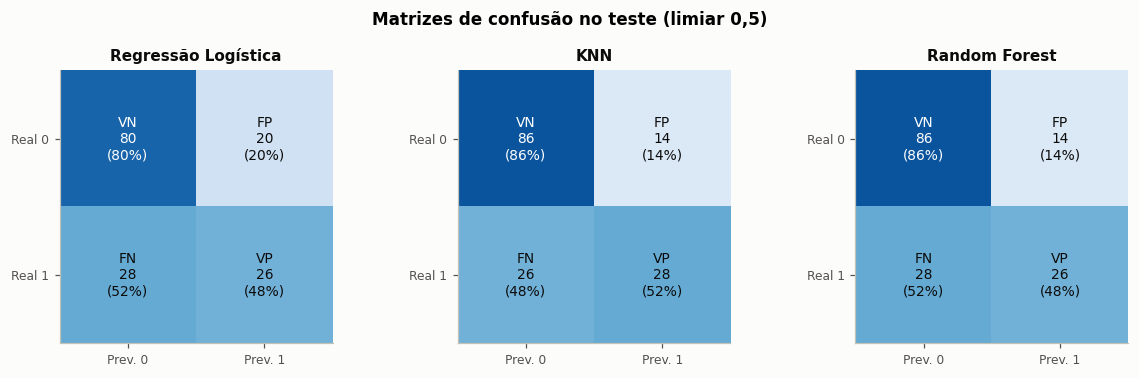

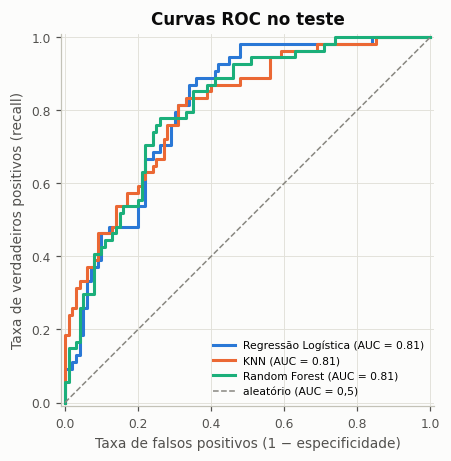

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, name in zip(axes, searches):
    plot_confusion_matrix(ax, y_test, test_pred[name], name)
fig.suptitle("Matrizes de confusão no teste (limiar 0,5)", fontsize=11, fontweight="semibold")
fig.tight_layout()
save_fig(fig, "11_matrizes_confusao_teste")
plt.show()

fig, ax = plt.subplots(figsize=(5, 4.4))
for (name, proba), color in zip(test_proba.items(), ["#2a78d6", "#eb6834", "#1baf7a"]):
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=ax, color=color, linewidth=2)
ax.plot([0, 1], [0, 1], color=NEUTRAL, linestyle="--", linewidth=1, label="aleatório (AUC = 0,5)")
ax.set_xlabel("Taxa de falsos positivos (1 − especificidade)")
ax.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax.set_title("Curvas ROC no teste")
ax.legend(fontsize=7, loc="lower right")
save_fig(fig, "12_curvas_roc_teste")
plt.show()

### Quão confiáveis são esses números? Intervalos de confiança por *bootstrap*

O teste tem só **54 diabéticas**: cada paciente a mais ou a menos detectada muda o recall em **1,9 ponto percentual**. Para medir essa incerteza, reamostramos as 154 pacientes de teste **com reposição** 2000 vezes e recalculamos as métricas a cada vez. O intervalo entre os percentis 2,5% e 97,5% é um **intervalo de confiança de 95%**.

In [9]:
ci_rows = []
for name in searches:
    ci = bootstrap_ci(y_test, test_pred[name], test_proba[name], n_boot=2000, seed=RANDOM_SEED)
    for metric in ["recall", "precisão", "f1", "roc_auc"]:
        ci_rows.append({"modelo": name, "métrica": metric, "teste": test_metrics.loc[name, metric],
                        "IC95% inferior": ci.loc[metric, "ic_inferior"],
                        "IC95% superior": ci.loc[metric, "ic_superior"]})
ci_table = pd.DataFrame(ci_rows)
ci_table.to_csv(TABLES_DIR / "ic_bootstrap_teste_python.csv", index=False)
ci_table.pivot(index="modelo", columns="métrica", values=["teste", "IC95% inferior", "IC95% superior"]).round(3)

teste                         IC95% inferior           \
métrica                 f1 precisão recall roc_auc             f1 precisão   
modelo                                                                       
KNN                  0.583    0.667  0.519   0.806          0.458    0.515   
Random Forest        0.553    0.650  0.481   0.807          0.424    0.500   
Regressão Logística  0.520    0.565  0.481   0.810          0.391    0.417   

                                   IC95% superior                          
métrica             recall roc_auc             f1 precisão recall roc_auc  
modelo                                                                     
KNN                  0.386   0.732          0.693    0.800  0.649   0.871  
Random Forest        0.345   0.733          0.661    0.795  0.614   0.871  
Regressão Logística  0.347   0.736          0.631    0.705  0.615   0.871

In [10]:
# Validação cruzada (treino) x teste: o teste está dentro da variação esperada?
cv_vs_test = []
for name, s in searches.items():
    res, i = s.cv_results_, s.best_index_
    for m_cv, m_test in [("roc_auc", "roc_auc"), ("acurácia", "acurácia"), ("recall", "recall"), ("f1", "f1")]:
        cv_vs_test.append({"modelo": name, "métrica": m_test,
                           "CV média": res[f"mean_test_{m_cv}"][i], "CV desvio": res[f"std_test_{m_cv}"][i],
                           "teste": test_metrics.loc[name, m_test]})
pd.DataFrame(cv_vs_test).pivot(index="modelo", columns="métrica", values=["CV média", "teste"]).round(3)

CV média                          teste                \
métrica             acurácia     f1 recall roc_auc acurácia     f1 recall   
modelo                                                                      
KNN                    0.763  0.609  0.531   0.838    0.740  0.583  0.519   
Random Forest          0.764  0.612  0.538   0.841    0.727  0.553  0.481   
Regressão Logística    0.780  0.640  0.568   0.845    0.688  0.520  0.481   

                             
métrica             roc_auc  
modelo                       
KNN                   0.806  
Random Forest         0.807  
Regressão Logística   0.810

**Observações**

- **No teste, com limiar 0,5:**

  | Modelo | ROC-AUC | Acurácia | Recall | F1 | Diabéticas detectadas |
  |---|---|---|---|---|---|
  | Regressão Logística | 0,810 | 0,688 | 0,481 | 0,520 | 26 de 54 |
  | KNN | 0,806 | 0,740 | 0,519 | 0,583 | 28 de 54 |
  | Random Forest | 0,807 | 0,727 | 0,481 | 0,553 | 26 de 54 |

  Os três modelos superam o baseline trivial de acurácia (0,651), mas **deixam passar quase metade das diabéticas** (26–28 falsos negativos). A especificidade é bem mais alta (0,80–0,86): com o limiar 0,5, os modelos "preferem" a classe majoritária.
- **Os intervalos de confiança são largos e se sobrepõem quase totalmente.** O recall do KNN, por exemplo, tem IC 95% de [0,39; 0,65], e a ROC-AUC de todos fica em torno de [0,73; 0,87]. **O teste não permite afirmar que um modelo é melhor que outro.** A vantagem do KNN em acurácia e F1 sobre a Regressão Logística corresponde a 2 diabéticas e 6 não diabéticas a mais classificadas corretamente, o que está dentro do ruído amostral.
- **O teste ficou abaixo da validação cruzada para os três modelos**: ROC-AUC caiu ≈ 0,03–0,04, e a acurácia da RL caiu de 0,780 para 0,688. Como a queda é parecida nos três modelos (inclusive na RL, que quase não tem hiperparâmetros para "sobreajustar"), a explicação mais provável não é *overfitting* na seleção de modelo, e sim que **esta amostra de 154 pacientes é mais difícil que a média**. Com um teste tão pequeno, variações dessa ordem são esperadas. Por isso os intervalos de confiança e a validação cruzada devem ser relatados junto com o resultado do teste.

## 5. O que os modelos aprenderam

- **Regressão Logística:** coeficientes com as variáveis padronizadas, ou seja, o efeito de +1 desvio-padrão. $e^{\text{coef}}$ é a **razão de chances**.
- **Random Forest:** **importância por permutação** no teste. Embaralhamos uma variável de cada vez e medimos quanto a ROC-AUC cai: se o modelo depende dela, a queda é grande. É mais confiável que a importância por impureza (Gini), que favorece variáveis contínuas com muitos valores distintos.

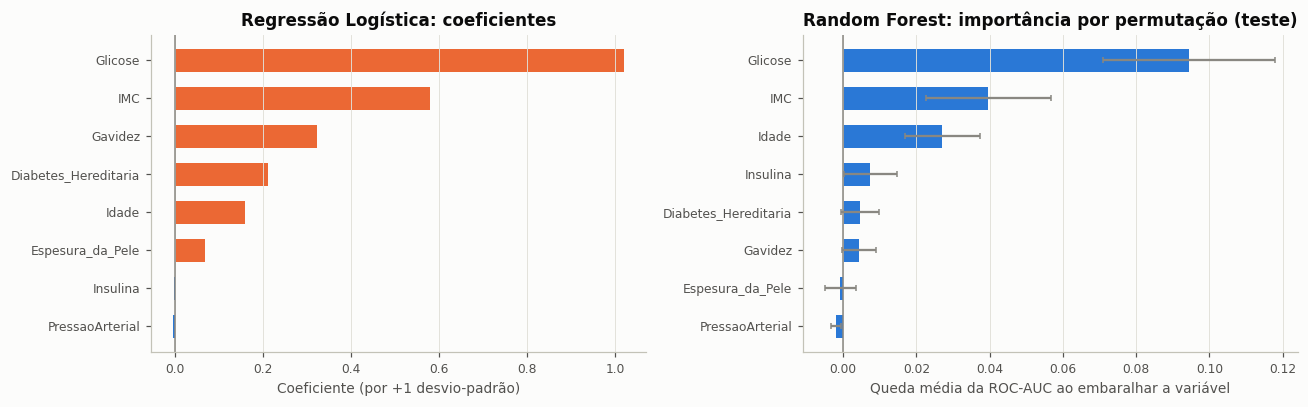

,coeficiente,razão_de_chances
Glicose,1.019,2.770
IMC,0.580,1.786
Gavidez,0.322,1.380
Diabetes_Hereditaria,0.210,1.234
Idade,0.158,1.171
Espesura_da_Pele,0.067,1.070
Insulina,-0.003,0.997
PressaoArterial,-0.004,0.996


,queda_auc_média,desvio
Glicose,9.445e-02,0.024
IMC,3.967e-02,0.017
Idade,2.709e-02,0.010
Insulina,7.469e-03,0.007
Diabetes_Hereditaria,4.685e-03,0.005
Gavidez,4.358e-03,0.005
Espesura_da_Pele,-7.160e-04,0.004
PressaoArterial,-1.901e-03,0.001


In [11]:
lr_model = searches["Regressão Logística"].best_estimator_.named_steps["modelo"]
lr_coef = pd.DataFrame({"coeficiente": lr_model.coef_.ravel(), "razão_de_chances": np.exp(lr_model.coef_.ravel())},
                       index=FEATURES).sort_values("coeficiente", ascending=False)
lr_coef.to_csv(TABLES_DIR / "coeficientes_regressao_logistica.csv")

perm = permutation_importance(searches["Random Forest"].best_estimator_, X_test, y_test, scoring="roc_auc",
                              n_repeats=30, random_state=RANDOM_SEED)
rf_imp = pd.DataFrame({"queda_auc_média": perm.importances_mean, "desvio": perm.importances_std},
                      index=FEATURES).sort_values("queda_auc_média", ascending=False)
rf_imp.to_csv(TABLES_DIR / "importancia_permutacao_rf.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
s = lr_coef["coeficiente"].iloc[::-1]
ax.barh(s.index, s.values, color=["#eb6834" if v > 0 else "#2a78d6" for v in s.values], height=0.6)
ax.axvline(0, color=NEUTRAL, linewidth=1)
ax.set_xlabel("Coeficiente (por +1 desvio-padrão)")
ax.set_title("Regressão Logística: coeficientes")
ax.grid(axis="y", visible=False)
ax = axes[1]
s = rf_imp.iloc[::-1]
ax.barh(s.index, s["queda_auc_média"], xerr=s["desvio"], color="#2a78d6", height=0.6,
        error_kw={"ecolor": NEUTRAL, "capsize": 2})
ax.axvline(0, color=NEUTRAL, linewidth=1)
ax.set_xlabel("Queda média da ROC-AUC ao embaralhar a variável")
ax.set_title("Random Forest: importância por permutação (teste)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "13_importancia_variaveis")
plt.show()

display(lr_coef)
rf_imp

**Observações**

- Os dois modelos concordam no essencial: **`Glicose` é de longe a variável mais importante**, seguida de **`IMC`**. Isso confirma a EDA (§7–8 do notebook 01).
  - Na Regressão Logística, +1 desvio-padrão de glicose multiplica a chance de diabetes por **2,8**, e de IMC por **1,8**.
  - No Random Forest, embaralhar a glicose derruba a ROC-AUC em ≈ 0,09; o IMC, em ≈ 0,04; a idade, em ≈ 0,03.
- `Gavidez` e `Diabetes_Hereditaria` contribuem moderadamente na RL. No RF, a `Idade` ocupa esse papel. Como `Idade` e `Gavidez` são correlacionadas (r = 0,54), os modelos podem "repartir" a mesma informação de formas diferentes.
- `PressaoArterial`, `Insulina` e `Espesura_da_Pele` têm contribuição **praticamente nula** nos dois modelos (coeficientes ≈ 0; queda de AUC ≈ 0 ou levemente negativa, isto é, ruído). Como discutido no notebook 03, a informação delas é em grande parte **redundante** com glicose e IMC.
- Os coeficientes são um pouco **menores** que os da regressão sem regularização do notebook 03 (glicose: 1,02 contra 1,21). Esse é o efeito esperado de C = 0,1: a penalidade L2 "encolhe" os pesos em direção a zero.

## 6. Priorizando o recall: escolha do limiar de decisão

Os modelos classificam como "diabetes" quando $\hat p \geq 0{,}5$. Esse valor é uma **convenção**, não uma lei: ele trata falsos positivos e falsos negativos como igualmente graves. Baixar o limiar detecta mais diabéticas (↑ recall) ao custo de mais alarmes falsos (↓ precisão).

**Como escolher o limiar sem tocar no teste:**

1. Obtemos probabilidades **out-of-fold** no treino (`cross_val_predict`, 5 folds): cada paciente de treino recebe a probabilidade de um modelo que **não a viu** no treino.
2. Escolhemos o limiar que maximiza o **F2** nessas probabilidades. O F2 é a média harmônica ponderada $F_\beta = (1+\beta^2)\frac{P\cdot R}{\beta^2 P + R}$ com $\beta = 2$, que considera o **recall 2× mais importante** que a precisão. Esse critério foi fixado **antes** de olhar qualquer resultado.
3. Aplicamos esse limiar, uma única vez, ao teste.

*Observação:* esta análise é uma **extensão** do enunciado. A comparação com o Orange (Fase 5) usa o limiar padrão de 0,5, que é o que o Orange aplica.

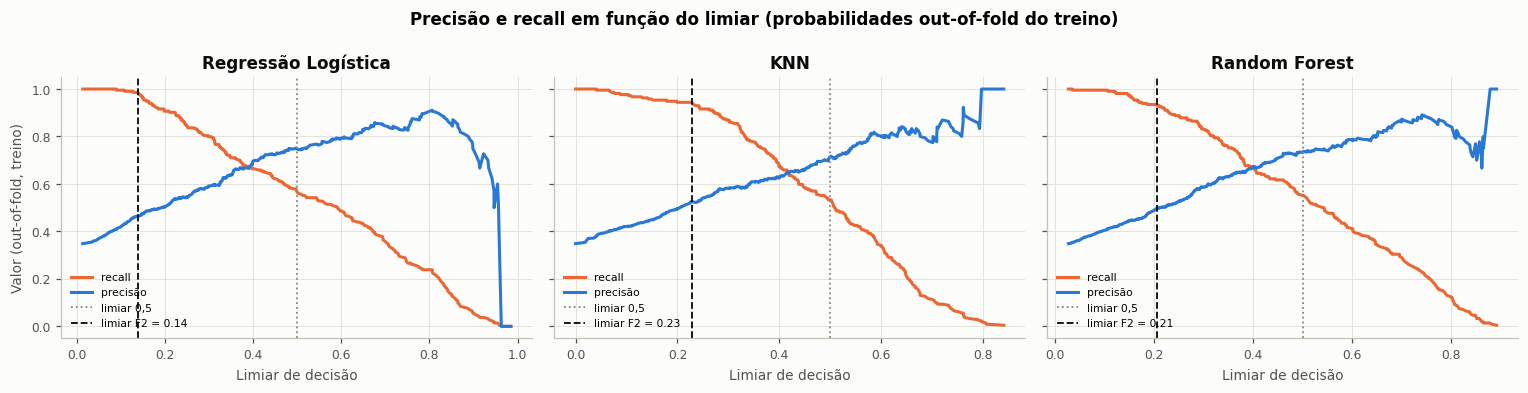

Regressão Logística    0.138
KNN                    0.229
Random Forest          0.205
Name: limiar escolhido (F2, out-of-fold), dtype: float64

In [12]:
oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
thresholds, oof_proba = {}, {}
for name, s in searches.items():
    oof_proba[name] = cross_val_predict(s.best_estimator_, X_train, y_train, cv=oof_cv, method="predict_proba")[:, 1]
    thresholds[name] = best_threshold_fbeta(y_train, oof_proba[name], beta=2)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, name in zip(axes, searches):
    precision, recall, thr = precision_recall_curve(y_train, oof_proba[name])
    ax.plot(thr, recall[:-1], color="#eb6834", linewidth=2, label="recall")
    ax.plot(thr, precision[:-1], color="#2a78d6", linewidth=2, label="precisão")
    ax.axvline(0.5, color=NEUTRAL, linestyle=":", linewidth=1.2, label="limiar 0,5")
    ax.axvline(thresholds[name], color="#0b0b0b", linestyle="--", linewidth=1.2,
               label=f"limiar F2 = {thresholds[name]:.2f}")
    ax.set_xlabel("Limiar de decisão")
    ax.set_title(name)
    ax.legend(fontsize=7, loc="lower left")
axes[0].set_ylabel("Valor (out-of-fold, treino)")
fig.suptitle("Precisão e recall em função do limiar (probabilidades out-of-fold do treino)",
             fontsize=11, fontweight="semibold")
fig.tight_layout()
save_fig(fig, "14_precisao_recall_limiar")
plt.show()

pd.Series(thresholds, name="limiar escolhido (F2, out-of-fold)").round(3)

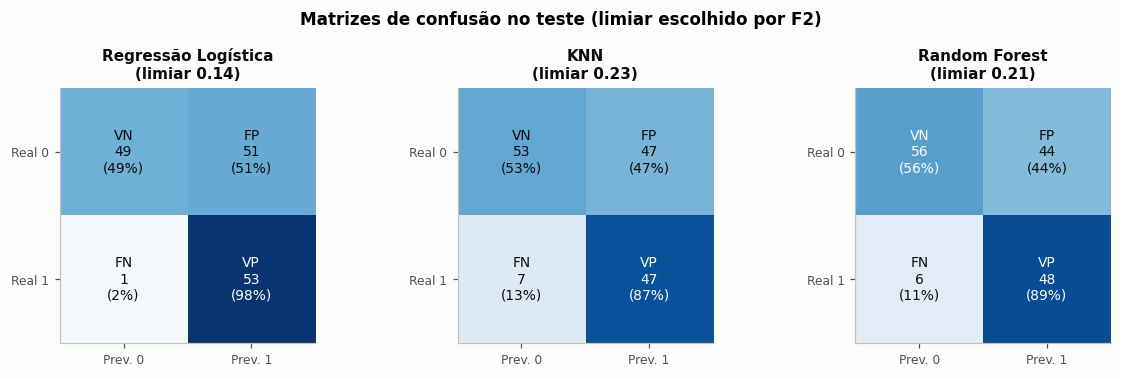

FN                   FP             acurácia  \
                    limiar 0,5 limiar F2 limiar 0,5 limiar F2 limiar 0,5   
Regressão Logística         28         1         20        51      0.688   
KNN                         26         7         14        47      0.740   
Random Forest               28         6         14        44      0.727   

                              especificidade                   f1            \
                    limiar F2     limiar 0,5 limiar F2 limiar 0,5 limiar F2   
Regressão Logística     0.662           0.80      0.49      0.520     0.671   
KNN                     0.649           0.86      0.53      0.583     0.635   
Random Forest           0.675           0.86      0.56      0.553     0.658   

                      precisão               recall            
                    limiar 0,5 limiar F2 limiar 0,5 limiar F2  
Regressão Logística      0.565     0.510      0.481     0.981  
KNN                      0.667     0.500      0.519     0.870  
Random Forest            0.650     0.522      0.481     0.889

In [13]:
tuned_pred = {name: (test_proba[name] >= thresholds[name]).astype(int) for name in searches}
tuned_metrics = pd.DataFrame({name: compute_metrics(y_test, tuned_pred[name], test_proba[name])
                              for name in searches}).T
tuned_metrics[["VN", "FP", "FN", "VP"]] = tuned_metrics[["VN", "FP", "FN", "VP"]].astype(int)
tuned_metrics.insert(0, "limiar", pd.Series(thresholds))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, name in zip(axes, searches):
    plot_confusion_matrix(ax, y_test, tuned_pred[name], f"{name}\n(limiar {thresholds[name]:.2f})")
fig.suptitle("Matrizes de confusão no teste (limiar escolhido por F2)", fontsize=11, fontweight="semibold")
fig.tight_layout()
save_fig(fig, "15_matrizes_confusao_teste_limiar_f2")
plt.show()

compare = pd.concat({"limiar 0,5": test_metrics[["acurácia", "precisão", "recall", "especificidade", "f1", "FN", "FP"]],
                     "limiar F2": tuned_metrics[["acurácia", "precisão", "recall", "especificidade", "f1", "FN", "FP"]]},
                    axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
compare

**Observações**

- Os limiares escolhidos por F2 são **bem menores que 0,5**: **0,14** (RL), **0,23** (KNN) e **0,21** (RF). As curvas mostram por quê: no treino (out-of-fold), o recall só começa a cair rapidamente acima de ≈ 0,2–0,3, enquanto a precisão sobe devagar.
- **Efeito no teste:**

  | Modelo | Recall 0,5 → F2 | FN 0,5 → F2 | FP 0,5 → F2 | F1 0,5 → F2 |
  |---|---|---|---|---|
  | Regressão Logística | 0,481 → **0,981** | 28 → **1** | 20 → 51 | 0,520 → 0,671 |
  | KNN | 0,519 → **0,870** | 26 → **7** | 14 → 47 | 0,583 → 0,635 |
  | Random Forest | 0,481 → **0,889** | 28 → **6** | 14 → 44 | 0,553 → 0,658 |

- Com o limiar ajustado, a **Regressão Logística detecta 53 das 54 diabéticas**. O preço é que **51 das 100 não diabéticas** recebem um alarme falso (especificidade 0,49). Esse recall não é sorte do teste: nas probabilidades out-of-fold do treino, o recall nesse limiar já era ≈ 0,98.
- **Isto ilustra a troca entre falsos negativos e falsos positivos.** Na RL, recuperar 27 diabéticas não detectadas custou 31 alarmes falsos a mais: cerca de 1 falso positivo extra para cada diabética recuperada. Em **triagem**, em que um falso positivo leva a um exame confirmatório barato, essa troca costuma valer a pena. Em um contexto em que o falso positivo fosse caro (tratamento invasivo, por exemplo), o limiar 0,5 ou um intermediário seria mais adequado. **A escolha do limiar é uma decisão clínica e de custo, não apenas estatística.**
- O F1 melhorou nos três modelos, o que mostra que o limiar 0,5 não era sequer o melhor equilíbrio entre precisão e recall para este problema desbalanceado.
- **A ROC-AUC não muda** com o limiar, porque mede a ordenação das probabilidades, que é a mesma. Só muda o ponto em que a curva ROC é "cortada".

## 7. Exportação dos resultados

In [14]:
export = pd.concat([
    test_metrics.assign(limiar=0.5, configuração="limiar 0,5"),
    tuned_metrics.assign(configuração="limiar F2"),
]).rename_axis("modelo").reset_index()
export.insert(0, "ferramenta", "Python (scikit-learn)")
export = export[["ferramenta", "modelo", "configuração", "limiar", *METRIC_ORDER, "VN", "FP", "FN", "VP"]]
export.to_csv(TABLES_DIR / "metricas_teste_python.csv", index=False)

probas = pd.DataFrame({"Resultado": y_test.values, **{f"proba_{n}": p for n, p in test_proba.items()}})
probas.to_csv(TABLES_DIR / "probabilidades_teste_python.csv", index=False)
print("Arquivos gravados em results/tables/:")
print("  metricas_teste_python.csv, probabilidades_teste_python.csv, hiperparametros_python.csv,")
print("  cv_melhores_modelos_python.csv, ic_bootstrap_teste_python.csv, coeficientes_regressao_logistica.csv,")
print("  importancia_permutacao_rf.csv, parametros_preprocessamento_treino.csv")
export.round(3)

Arquivos gravados em results/tables/:
  metricas_teste_python.csv, probabilidades_teste_python.csv, hiperparametros_python.csv,
  cv_melhores_modelos_python.csv, ic_bootstrap_teste_python.csv, coeficientes_regressao_logistica.csv,
  importancia_permutacao_rf.csv, parametros_preprocessamento_treino.csv


,ferramenta,modelo,configuração,limiar,acurácia,precisão,recall,especificidade,f1,roc_auc,VN,FP,FN,VP
0,Python (scikit-learn),Regressão Logística,"limiar 0,5",0.500,0.688,0.565,0.481,0.80,0.520,0.810,80,20,28,26
1,Python (scikit-learn),KNN,"limiar 0,5",0.500,0.740,0.667,0.519,0.86,0.583,0.806,86,14,26,28
2,Python (scikit-learn),Random Forest,"limiar 0,5",0.500,0.727,0.650,0.481,0.86,0.553,0.807,86,14,28,26
3,Python (scikit-learn),Regressão Logística,limiar F2,0.138,0.662,0.510,0.981,0.49,0.671,0.810,49,51,1,53
4,Python (scikit-learn),KNN,limiar F2,0.229,0.649,0.500,0.870,0.53,0.635,0.806,53,47,7,47
5,Python (scikit-learn),Random Forest,limiar F2,0.205,0.675,0.522,0.889,0.56,0.658,0.807,56,44,6,48


## Conclusões deste notebook

1. **Os três algoritmos têm desempenho estatisticamente equivalente** neste dataset: ROC-AUC ≈ 0,84 na validação cruzada e ≈ 0,81 no teste, com intervalos de confiança amplamente sobrepostos. Abordagens bem diferentes (linear, por distâncias, ensemble de árvores) chegarem ao mesmo patamar sugere que o limite está na **informação contida nas 8 variáveis**, e não na escolha do algoritmo.
2. **A Regressão Logística é a escolha recomendada.** Com desempenho empatado, ela é a mais simples, a mais estável e a única diretamente interpretável (razões de chances). Também foi a que atingiu o maior recall com o limiar ajustado. (Critério de parcimônia: entre modelos equivalentes, prefere-se o mais simples.)
3. **Com o limiar padrão de 0,5, todos os modelos são inadequados para triagem**: deixam passar ≈ 50% das diabéticas. **Ajustar o limiar** (escolhido sem usar o teste) eleva o recall para 0,87–0,98, ao custo de mais falsos positivos.
4. **Glicose e IMC** concentram a maior parte do poder preditivo; pressão arterial, insulina e dobra cutânea acrescentam pouco quando as demais variáveis já estão no modelo.
5. **Limitação metodológica:** com só 54 diabéticas no teste, as métricas têm incerteza de ±10 pontos percentuais ou mais. Diferenças menores que isso entre modelos, ou entre Python e Orange (Fase 5), não devem ser interpretadas como reais.